In [1]:

import pandas as pd
import os

base_path = r"D:\RouteRanker\data\model_ready"

cities = [
    "delhi",
    "hyderabad",
    "bengaluru",
    "chennai",
    "mumbai",
    "pune"
]

city_data_m5 = {}

for city in cities:
    file_path = os.path.join(base_path, f"{city}_processed.csv")

    city_data_m5[city] = pd.read_csv(file_path)

    print(city.upper(), city_data_m5[city].shape)

print("\nAll six processed datasets loaded successfully!")


DELHI (2403, 5)
HYDERABAD (1031, 5)
BENGALURU (4434, 5)
CHENNAI (4611, 5)
MUMBAI (1609, 5)
PUNE (628, 5)

All six processed datasets loaded successfully!


#Find the best number of clusters using the Elbow Method

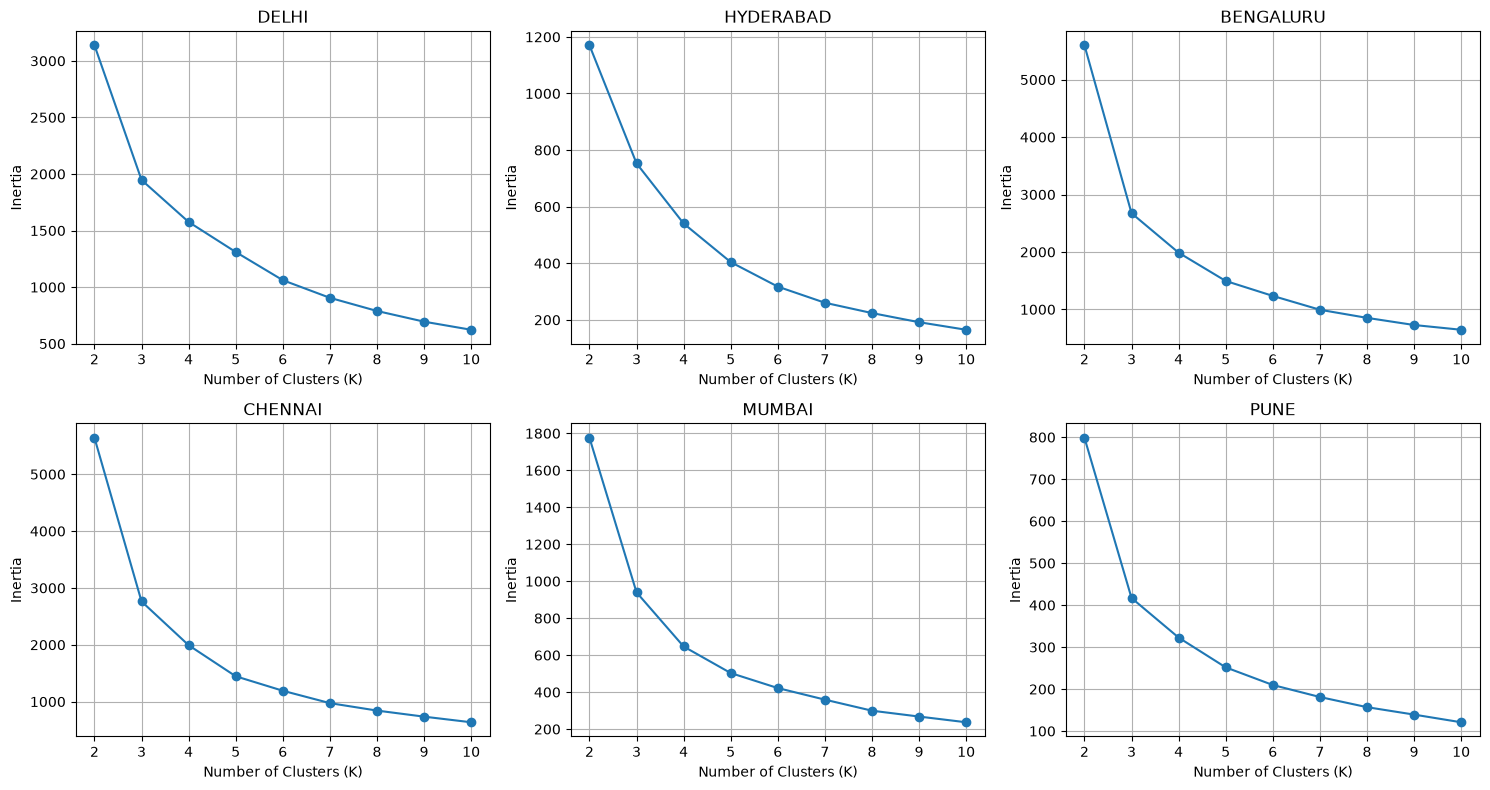

In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

features = ["total_trips_scaled", "total_stops_scaled"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, city in enumerate(cities):
    X = city_data_m5[city][features]

    inertia_values = []

    for k in range(2, 11):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    axes[i].plot(range(2, 11), inertia_values, marker="o")
    axes[i].set_title(city.upper())
    axes[i].set_xlabel("Number of Clusters (K)")
    axes[i].set_ylabel("Inertia")
    axes[i].grid(True)

plt.tight_layout()
plt.show()

#Silhouette Score,Davies-Bouldin Index,Inertia

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

results = []

features = ["total_trips_scaled", "total_stops_scaled"]

for city in cities:
    X = city_data_m5[city][features]

    for k in range(2, 9):
        model = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = model.fit_predict(X)

        results.append({
            "City": city.upper(),
            "K": k,
            "Inertia": round(model.inertia_, 3),
            "Silhouette Score": round(silhouette_score(X, labels), 3),
            "Davies-Bouldin Index": round(davies_bouldin_score(X, labels), 3)
        })

evaluation_df = pd.DataFrame(results)

display(evaluation_df)

,City,K,Inertia,Silhouette Score,Davies-Bouldin Index
0,DELHI,2,3138.242,0.498,0.889
1,DELHI,3,1947.202,0.406,0.820
2,DELHI,4,1575.953,0.363,0.877
3,DELHI,5,1310.535,0.360,0.758
4,DELHI,6,1061.339,0.379,0.742
5,DELHI,7,905.553,0.386,0.751
6,DELHI,8,789.241,0.355,0.793
7,HYDERABAD,2,1170.614,0.816,0.655
8,HYDERABAD,3,753.021,0.705,0.678
9,HYDERABAD,4,540.564,0.478,0.727


#Select K values and implement K-Means

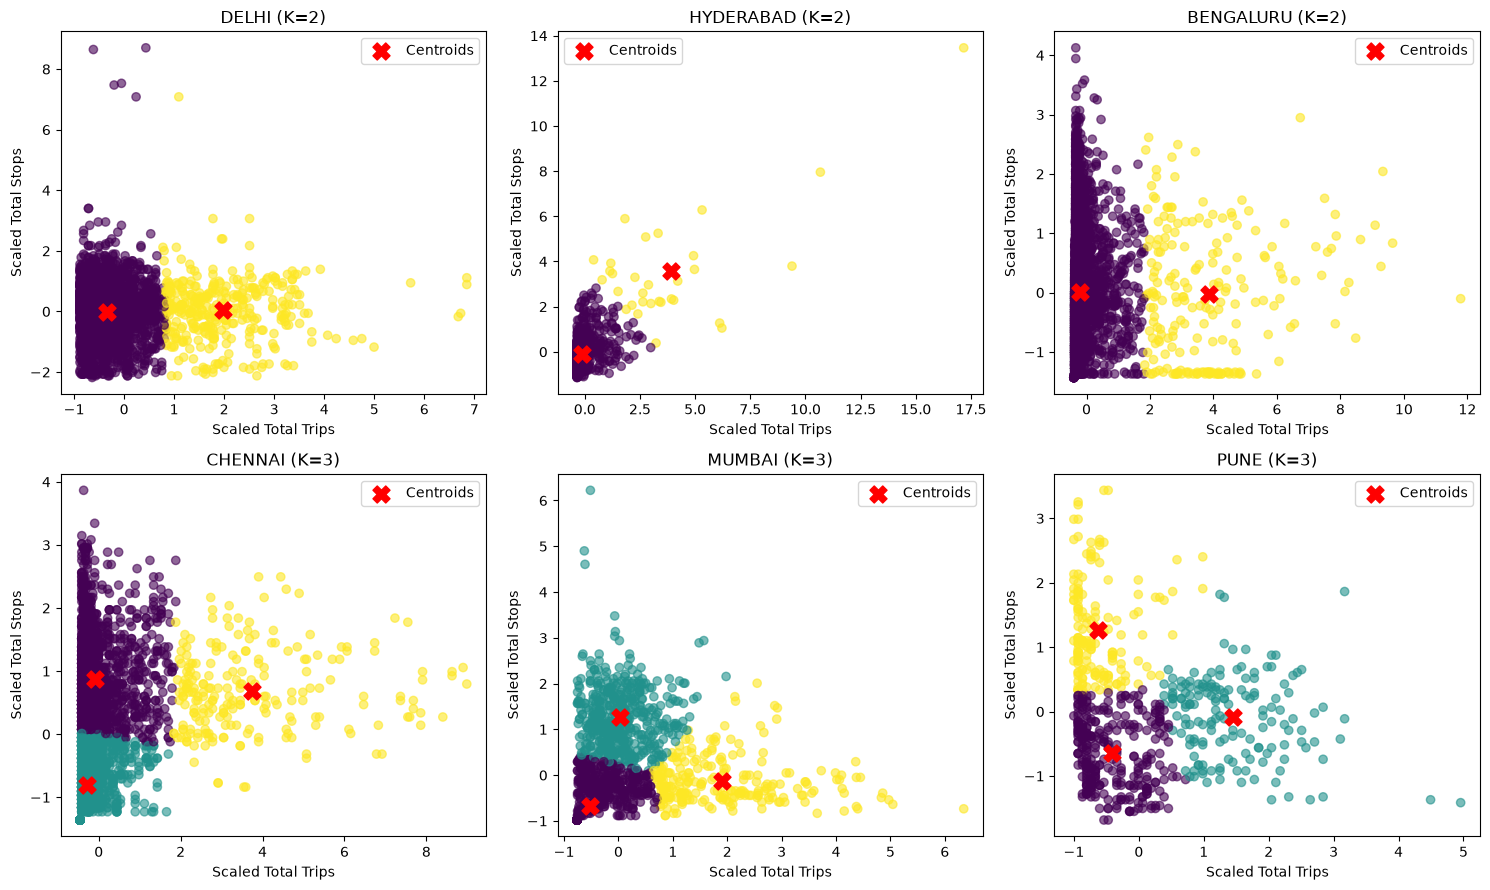

K-Means clustering completed for all six cities!


In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

selected_k = {
    "delhi": 2,
    "hyderabad": 2,
    "bengaluru": 2,
    "chennai": 3,
    "mumbai": 3,
    "pune": 3
}

kmeans_models = {}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, city in enumerate(cities):

    X = city_data_m5[city][features]

    k = selected_k[city]

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X)

    city_data_m5[city]["KMeans_Cluster"] = labels

    kmeans_models[city] = model

    axes[i].scatter(
        X["total_trips_scaled"],
        X["total_stops_scaled"],
        c=labels,
        cmap="viridis",
        alpha=0.6
    )

    axes[i].scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        marker="X",
        s=150,
        color="red",
        label="Centroids"
    )

    axes[i].set_title(f"{city.upper()} (K={k})")
    axes[i].set_xlabel("Scaled Total Trips")
    axes[i].set_ylabel("Scaled Total Stops")
    axes[i].legend()

plt.tight_layout()
plt.show()

print("K-Means clustering completed for all six cities!")

#Implementation of DBSCAN

In [5]:
from sklearn.cluster import DBSCAN

dbscan_results = []

eps_values = [0.3, 0.5, 0.7, 1.0]

for city in cities:
    X = city_data_m5[city][features]

    for eps in eps_values:
        model = DBSCAN(eps=eps, min_samples=5)
        labels = model.fit_predict(X)

        clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_points = list(labels).count(-1)

        dbscan_results.append({
            "City": city.upper(),
            "Eps": eps,
            "Min Samples": 5,
            "Number of Clusters": clusters,
            "Noise Points": noise_points
        })

dbscan_df = pd.DataFrame(dbscan_results)

display(dbscan_df)

,City,Eps,Min Samples,Number of Clusters,Noise Points
0,DELHI,0.3,5,3,56
1,DELHI,0.5,5,1,22
2,DELHI,0.7,5,1,16
3,DELHI,1.0,5,1,11
4,HYDERABAD,0.3,5,2,51
5,HYDERABAD,0.5,5,1,31
6,HYDERABAD,0.7,5,1,18
7,HYDERABAD,1.0,5,1,11
8,BENGALURU,0.3,5,4,92
9,BENGALURU,0.5,5,3,29


#DBSCAN FOR ALL SIX CITIES

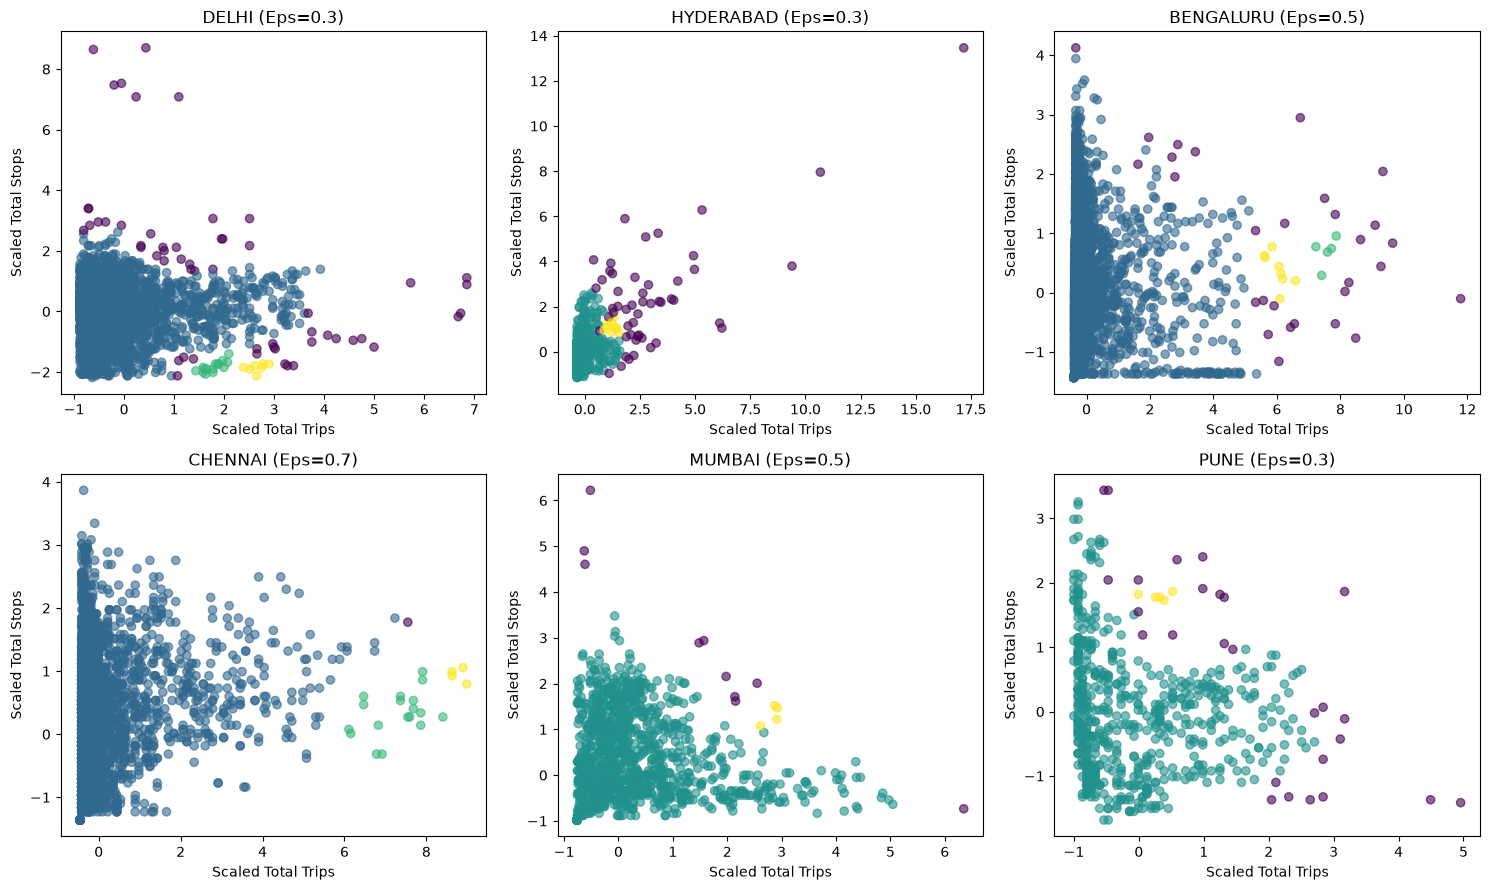

DBSCAN clustering completed for all six cities!


In [6]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt

selected_eps = {
    "delhi": 0.3,
    "hyderabad": 0.3,
    "bengaluru": 0.5,
    "chennai": 0.7,
    "mumbai": 0.5,
    "pune": 0.3
}

dbscan_models = {}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, city in enumerate(cities):

    X = city_data_m5[city][features]

    model = DBSCAN(eps=selected_eps[city], min_samples=5)

    labels = model.fit_predict(X)

    city_data_m5[city]["DBSCAN_Cluster"] = labels

    dbscan_models[city] = model

    axes[i].scatter(
        X["total_trips_scaled"],
        X["total_stops_scaled"],
        c=labels,
        cmap="viridis",
        alpha=0.6
    )

    axes[i].set_title(f"{city.upper()} (Eps={selected_eps[city]})")
    axes[i].set_xlabel("Scaled Total Trips")
    axes[i].set_ylabel("Scaled Total Stops")

plt.tight_layout()
plt.show()

print("DBSCAN clustering completed for all six cities!")

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

dbscan_evaluation = []

for city in cities:

    X = city_data_m5[city][features]
    labels = city_data_m5[city]["DBSCAN_Cluster"]

    noise_count = (labels == -1).sum()

    # Exclude noise points for cluster quality evaluation
    non_noise = labels != -1
    X_clean = X[non_noise]
    labels_clean = labels[non_noise]

    n_clusters = len(set(labels_clean))

    if n_clusters >= 2 and len(X_clean) > n_clusters:

        silhouette = silhouette_score(X_clean, labels_clean)
        db_index = davies_bouldin_score(X_clean, labels_clean)

    else:
        silhouette = None
        db_index = None

    dbscan_evaluation.append({
        "City": city.upper(),
        "Clusters": n_clusters,
        "Noise Points": noise_count,
        "Silhouette Score": round(silhouette, 3) if silhouette is not None else "Not available",
        "Davies-Bouldin Index": round(db_index, 3) if db_index is not None else "Not available"
    })

dbscan_evaluation_df = pd.DataFrame(dbscan_evaluation)

display(dbscan_evaluation_df)

,City,Clusters,Noise Points,Silhouette Score,Davies-Bouldin Index
0,DELHI,3,56,0.422,0.495
1,HYDERABAD,2,51,0.559,0.436
2,BENGALURU,3,29,0.754,0.342
3,CHENNAI,3,1,0.783,0.429
4,MUMBAI,2,10,0.465,0.446
5,PUNE,2,27,0.219,0.702


K-Means and DBSCAN trained models.
Route cluster assignments for all six cities.
Evaluation and comparison tables.
DBSCAN parameter experiment results.

In [8]:
import os
import joblib
import pandas as pd

output_path = r"D:\RouteRanker\data\model_results"
os.makedirs(output_path, exist_ok=True)

# Select K-Means evaluation results for the chosen K values
selected_results = []

for city in cities:
    k = selected_k[city]

    row = evaluation_df[
        (evaluation_df["City"] == city.upper()) &
        (evaluation_df["K"] == k)
    ].iloc[0]

    selected_results.append(row)

kmeans_selected_df = pd.DataFrame(selected_results)

# Compare K-Means and DBSCAN
comparison_df = kmeans_selected_df.merge(
    dbscan_evaluation_df,
    on="City",
    suffixes=("_KMeans", "_DBSCAN")
)

# Save route assignments for every city
for city in cities:
    city_data_m5[city].to_csv(
        os.path.join(output_path, f"{city}_clustered_routes.csv"),
        index=False
    )

# Save trained models
joblib.dump(kmeans_models, os.path.join(output_path, "kmeans_models.joblib"))
joblib.dump(dbscan_models, os.path.join(output_path, "dbscan_models.joblib"))

# Save evaluation tables
kmeans_selected_df.to_csv(
    os.path.join(output_path, "kmeans_evaluation.csv"), index=False
)

dbscan_evaluation_df.to_csv(
    os.path.join(output_path, "dbscan_evaluation.csv"), index=False
)

dbscan_df.to_csv(
    os.path.join(output_path, "dbscan_parameter_experiments.csv"), index=False
)

comparison_df.to_csv(
    os.path.join(output_path, "clustering_comparison.csv"), index=False
)

print("All Module 5 results saved successfully!")
print("Saved location:", output_path)

display(comparison_df)

All Module 5 results saved successfully!
Saved location: D:\RouteRanker\data\model_results


,City,K,Inertia,Silhouette Score_KMeans,Davies-Bouldin Index_KMeans,Clusters,Noise Points,Silhouette Score_DBSCAN,Davies-Bouldin Index_DBSCAN
0,DELHI,2,3138.242,0.498,0.889,3,56,0.422,0.495
1,HYDERABAD,2,1170.614,0.816,0.655,2,51,0.559,0.436
2,BENGALURU,2,5600.128,0.698,0.665,3,29,0.754,0.342
3,CHENNAI,3,2762.198,0.517,0.657,3,1,0.783,0.429
4,MUMBAI,3,939.619,0.568,0.695,2,10,0.465,0.446
5,PUNE,3,416.957,0.457,0.757,2,27,0.219,0.702


## The results show:
- K-Means: Hyderabad has the highest Silhouette Score (0.816).
- DBSCAN: Chennai has the highest Silhouette Score (0.783).
- DBSCAN: Bengaluru has the lowest Davies-Bouldin Index (0.342).
- Noise analysis: DBSCAN identified 56 noise points in Delhi and only 1 in Chennai.